# Juice Dataset Analysis & Machine Learning

**Goal:** clean a juice sales dataset, explore it with charts, and train one simple machine learning model to predict how many units of a juice product get sold.

> **Note on the data:** the dataset in this project (`data/juice_dataset.csv`) is **simulated**, not real store data. I generated it with `src/generate_dataset.py` and added realistic problems (missing values, duplicates, typos) so the cleaning steps have real work to do. Because I wrote the rules that create the data, the patterns found here are *not* findings about the real juice market. The point of the project is the workflow: cleaning, EDA and a regression model.

**Target for the model:** `quantity_sold`

## 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 3. Load Dataset

In [2]:
df = pd.read_csv("../data/juice_dataset.csv")
df.head()

          product_name     category  pack_size_ml  price  discount_pct  quantity_sold  rating  sugar_g_per_100ml is_organic  month region   revenue
0        PureSip Mango        Mango           250  16.03             0          208.0     4.7               13.6         No      3   East   3334.24
1      GreenLeaf Berry        Berry           250  17.06            10          188.0     4.1                9.4         No     11  North   2886.55
2      DailyGlow Grape        Grape           200  12.84            10          160.0     3.8               14.4        Yes      1   West   1848.96
3  PureSip Mixed Fruit  Mixed Fruit          1000  47.42             0          215.0     3.4               12.3         No     10   East  10195.30
4   FreshSqueeze Apple        Apple           500    NaN             0          160.0     4.6                7.4        Yes      3  North   6414.40

In [3]:
df.tail()

           product_name   category  pack_size_ml  price  discount_pct  quantity_sold  rating  sugar_g_per_100ml is_organic  month region  revenue
660       PureSip Grape      Grape           250  13.64            10          181.0     3.6               14.3         No      2   East  2221.96
661     DailyGlow Apple      Apple          1000  40.85            15          248.0     4.5                8.8         No     12  South  8611.18
662       PureSip Berry      Berry           500  29.26             0          155.0     4.3                7.8         No      1   West  4535.30
663  FreshSqueeze Apple      Apple           500  28.90             0          256.0     4.3               10.9         No      4   East  7398.40
664   TropiCo Pineapple  Pineapple           200   9.34            20          237.0     3.8                9.8         No     12  North  1770.86

## 4. Dataset Overview

| Column | Meaning |
|---|---|
| `product_name` | Brand + flavor, e.g. "PureSip Mango" |
| `category` | Juice flavor |
| `pack_size_ml` | Bottle size in millilitres |
| `price` | List price of one bottle |
| `discount_pct` | Discount applied (%) |
| `quantity_sold` | Units sold (**target**) |
| `rating` | Average customer rating (1-5) |
| `sugar_g_per_100ml` | Sugar content |
| `is_organic` | Organic or not |
| `month` | Month of the sales record (1-12) |
| `region` | Sales region |
| `revenue` | Price after discount x quantity sold |

In [4]:
print("Shape:", df.shape)
df.info()

Shape: (665, 12)
<class 'pandas.DataFrame'>
RangeIndex: 665 entries, 0 to 664
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_name       665 non-null    str    
 1   category           665 non-null    str    
 2   pack_size_ml       665 non-null    int64  
 3   price              653 non-null    float64
 4   discount_pct       665 non-null    int64  
 5   quantity_sold      656 non-null    float64
 6   rating             636 non-null    float64
 7   sugar_g_per_100ml  643 non-null    float64
 8   is_organic         665 non-null    str    
 9   month              665 non-null    int64  
 10  region             665 non-null    str    
 11  revenue            650 non-null    float64
dtypes: float64(5), int64(3), str(4)
memory usage: 62.5 KB


In [5]:
df.describe()

       pack_size_ml       price  discount_pct  quantity_sold      rating  sugar_g_per_100ml       month       revenue
count    665.000000  653.000000    665.000000     656.000000  636.000000         643.000000  665.000000    650.000000
mean     486.315789   29.184043      6.413534     232.018293    4.160220          10.219285    6.425564   6028.429292
std      297.784170   23.751612      6.582571      60.691584    1.701812           2.301760    3.466398   4040.201105
min      200.000000    7.610000      0.000000     -20.000000    0.000000           5.600000    1.000000   1026.590000
25%      250.000000   13.640000      0.000000     190.000000    3.800000           8.500000    3.000000   2864.710000
50%      500.000000   23.480000      5.000000     229.000000    4.100000           9.800000    6.000000   4762.020000
75%      500.000000   37.970000     10.000000     276.000000    4.400000          11.800000    9.000000   7919.945000
max     1000.000000  233.000000     20.000000     406.00

In [6]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
product_name          0
category              0
pack_size_ml          0
price                12
discount_pct          0
quantity_sold         9
rating               29
sugar_g_per_100ml    22
is_organic            0
month                 0
region                0
revenue              15
dtype: int64

Duplicate rows: 15


In [7]:
print("category values:", sorted(df["category"].unique()))
print("is_organic values:", df["is_organic"].unique())

category values: [' Apple ', ' Mango ', ' Mixed Fruit ', ' Orange ', 'APPLE', 'Apple', 'Berry', 'GRAPE', 'Grape', 'MANGO', 'Mango', 'Mixed Fruit', 'ORANGE', 'Orange', 'PINEAPPLE', 'Pineapple', 'apple', 'berry', 'mango', 'mixed fruit', 'orange']
is_organic values: <StringArray>
['No', 'Yes', 'N', 'no', 'Y', 'yes']
Length: 6, dtype: str


**What the overview shows**

- Some columns have missing values (`rating`, `sugar_g_per_100ml`, `price`, `revenue`, `quantity_sold`).
- There are duplicate rows.
- `category` is written in several ways (`ORANGE`, ` Orange `, `orange`) and `is_organic` mixes `Yes/yes/Y/No/no/N`.
- `quantity_sold` is a float only because it has missing values, and its minimum is negative, which is impossible.
- The max of `rating` is far above 5 and the max of `price` looks too large. I look at both next.

## 5. Data Cleaning

Each decision and why:

1. **Standardise text values** so the same category is not counted as several. Convert `is_organic` to True/False.
2. **Drop duplicate rows**: the same record twice would be counted twice in every total and in the model.
3. **Invalid ratings** (outside 1-5) are set to missing, because they are data-entry errors.
4. **Drop rows with missing or non-positive `quantity_sold`**: this is the target, so I don't want to guess it.
5. **Price outliers**: a price more than 3x the usual price for the same pack size looks like a decimal-point typo, so I set it to missing.
6. **Fill missing values with medians** (price by pack size, rating and sugar by category). Median is not pulled around by extreme values.
7. **Recompute `revenue`** from price, discount and quantity, because it was partly missing and depends on the price I just fixed.

In [8]:
clean = df.copy()
rows_start = len(clean)

clean["category"] = clean["category"].str.strip().str.title()
clean["is_organic"] = clean["is_organic"].str.strip().str.lower().map(
    {"yes": True, "y": True, "no": False, "n": False}
)
print("categories now:", sorted(clean["category"].unique()))

categories now: ['Apple', 'Berry', 'Grape', 'Mango', 'Mixed Fruit', 'Orange', 'Pineapple']


In [9]:
clean = clean.drop_duplicates()
print("Rows removed as duplicates:", rows_start - len(clean))

Rows removed as duplicates: 15


In [10]:
# look at the suspicious values before changing them
print("Ratings outside 1-5:")
bad_rating = clean["rating"].notna() & ~clean["rating"].between(1, 5)
print(clean.loc[bad_rating, "rating"].tolist())

typical_price = clean.groupby("pack_size_ml")["price"].transform("median")
price_typos = clean["price"] > 3 * typical_price
print("\nPrice values flagged as typos:", price_typos.sum())
print(clean.loc[price_typos, ["pack_size_ml", "price"]])

Ratings outside 1-5:
[9.5, 0.0, 45.0, 7.0]

Price values flagged as typos: 4
     pack_size_ml  price
34           1000  233.0
143           250  233.0
159           500  233.0
303          1000  233.0


In [11]:
clean.loc[bad_rating, "rating"] = np.nan
clean.loc[price_typos, "price"] = np.nan

before = len(clean)
clean = clean[clean["quantity_sold"] > 0].copy()   # also drops missing quantities
print("Rows dropped for bad/missing quantity_sold:", before - len(clean))

Rows dropped for bad/missing quantity_sold: 10


In [12]:
clean["price"] = clean["price"].fillna(clean.groupby("pack_size_ml")["price"].transform("median"))
for col in ["rating", "sugar_g_per_100ml"]:
    clean[col] = clean[col].fillna(clean.groupby("category")[col].transform("median"))

clean["quantity_sold"] = clean["quantity_sold"].astype(int)
clean["revenue"] = (clean["price"] * (1 - clean["discount_pct"] / 100) * clean["quantity_sold"]).round(2)
clean = clean.reset_index(drop=True)

print("Missing values left:", clean.isnull().sum().sum())
print("Shape: raw", df.shape, "-> clean", clean.shape)
clean.dtypes

Missing values left: 0
Shape: raw (665, 12) -> clean (640, 12)


product_name             str
category                 str
pack_size_ml           int64
price                float64
discount_pct           int64
quantity_sold          int64
rating               float64
sugar_g_per_100ml    float64
is_organic              bool
month                  int64
region                   str
revenue              float64

After cleaning there are no missing values, categories are consistent and the data types make sense (`quantity_sold` is an integer, `is_organic` is boolean). I lost 25 rows out of 665 (duplicates plus rows with no usable target), which is a small price for reliable data.

## 6. Exploratory Data Analysis

### 6.1 Which products sell the most?

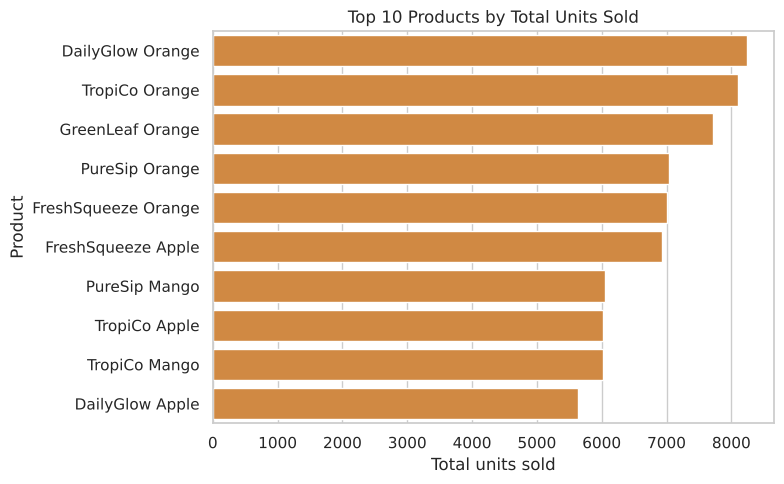

In [13]:
top_products = clean.groupby("product_name")["quantity_sold"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_products.values, y=top_products.index, color="#e8892b")
plt.title("Top 10 Products by Total Units Sold")
plt.xlabel("Total units sold")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig("../images/top_products.png", dpi=120)
plt.show()

The top products are all **Orange** juices from different brands. Flavor seems to matter more than brand, which I check in 6.5.

### 6.2 How are sales distributed?

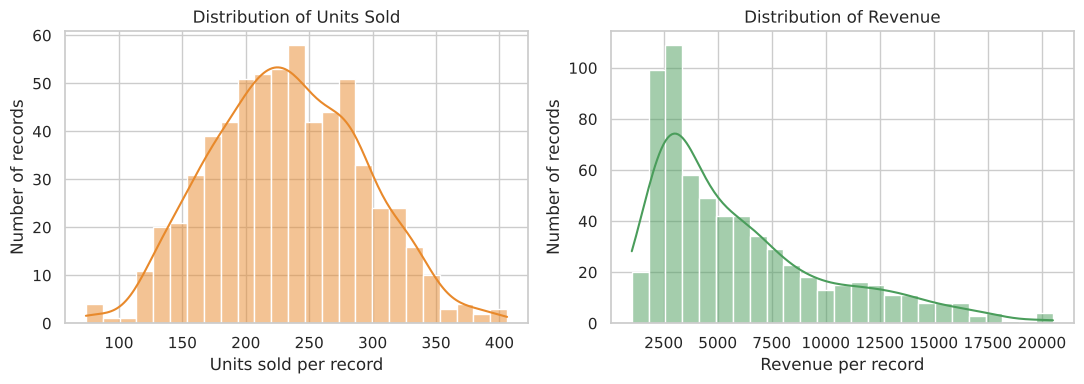

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(clean["quantity_sold"], bins=25, kde=True, ax=axes[0], color="#e8892b")
axes[0].set_title("Distribution of Units Sold")
axes[0].set_xlabel("Units sold per record")
axes[0].set_ylabel("Number of records")

sns.histplot(clean["revenue"], bins=25, kde=True, ax=axes[1], color="#4a9d5b")
axes[1].set_title("Distribution of Revenue")
axes[1].set_xlabel("Revenue per record")
axes[1].set_ylabel("Number of records")
plt.tight_layout()
plt.savefig("../images/sales_distribution.png", dpi=120)
plt.show()

Units sold is roughly bell-shaped around 230. Revenue is right-skewed: most records are small and a few large records (big bottles that sold well) pull the tail out.

### 6.3 How are prices distributed, and how do they relate to sales?

Correlation price vs quantity: -0.04
Correlation price_per_100ml vs quantity: -0.36


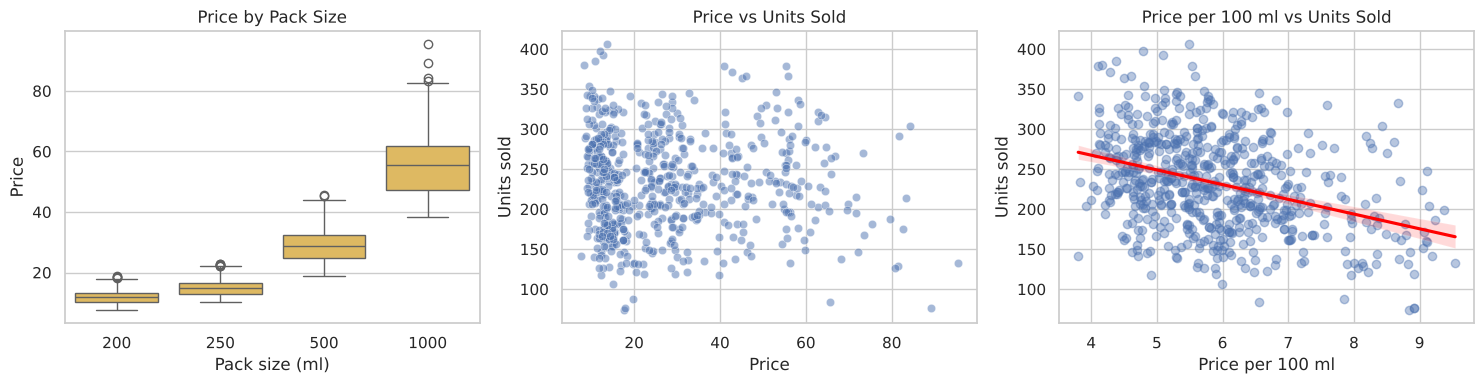

In [15]:
clean["price_per_100ml"] = clean["price"] / clean["pack_size_ml"] * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=clean, x="pack_size_ml", y="price", ax=axes[0], color="#f2c14e")
axes[0].set_title("Price by Pack Size")
axes[0].set_xlabel("Pack size (ml)")
axes[0].set_ylabel("Price")

sns.scatterplot(data=clean, x="price", y="quantity_sold", alpha=0.5, ax=axes[1])
axes[1].set_title("Price vs Units Sold")
axes[1].set_xlabel("Price")
axes[1].set_ylabel("Units sold")

sns.regplot(data=clean, x="price_per_100ml", y="quantity_sold",
            scatter_kws={"alpha": 0.4}, line_kws={"color": "red"}, ax=axes[2])
axes[2].set_title("Price per 100 ml vs Units Sold")
axes[2].set_xlabel("Price per 100 ml")
axes[2].set_ylabel("Units sold")
plt.tight_layout()
plt.savefig("../images/price_vs_sales.png", dpi=120)
plt.show()

print("Correlation price vs quantity:", round(clean["price"].corr(clean["quantity_sold"]), 2))
print("Correlation price_per_100ml vs quantity:", round(clean["price_per_100ml"].corr(clean["quantity_sold"]), 2))

Raw `price` barely relates to units sold (correlation about -0.04), because price is mostly decided by **bottle size**. A bigger bottle costs more but isn't "more expensive". Once I compare **price per 100 ml**, a clear negative relationship shows up (about -0.36): juices that are pricier per ml sell fewer units. This is why I created `price_per_100ml` as a feature.

### 6.4 How are ratings distributed?

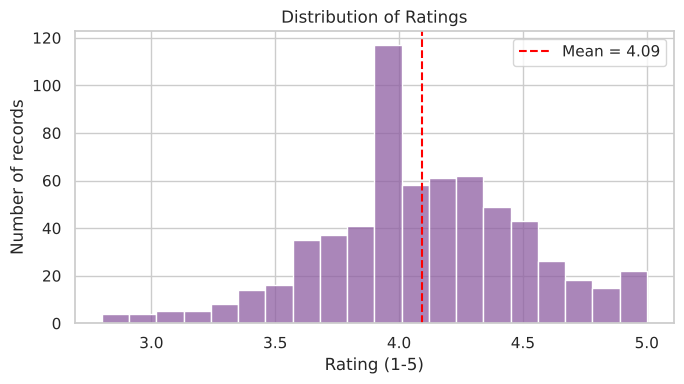

In [16]:
plt.figure(figsize=(7, 4))
sns.histplot(clean["rating"], bins=20, color="#8e5ea2")
plt.axvline(clean["rating"].mean(), color="red", linestyle="--", label=f"Mean = {clean['rating'].mean():.2f}")
plt.title("Distribution of Ratings")
plt.xlabel("Rating (1-5)")
plt.ylabel("Number of records")
plt.legend()
plt.tight_layout()
plt.savefig("../images/rating_distribution.png", dpi=120)
plt.show()

Ratings are concentrated between about 3.8 and 4.4 with a mean of about 4.1. There are very few low ratings.

### 6.5 How do flavors compare?

In [17]:
cat_summary = clean.groupby("category").agg(
    avg_units=("quantity_sold", "mean"),
    avg_rating=("rating", "mean"),
    avg_sugar=("sugar_g_per_100ml", "mean"),
    total_revenue=("revenue", "sum"),
).round(1).sort_values("avg_units", ascending=False)
cat_summary

             avg_units  avg_rating  avg_sugar  total_revenue
category                                                    
Orange           278.1         4.3        8.1      1020727.4
Apple            252.6         4.1        9.0       721849.8
Mango            251.7         4.3       12.5       605720.7
Mixed Fruit      220.4         3.9       10.2       413081.7
Pineapple        196.4         3.9       10.9       366518.4
Berry            194.7         4.2        8.8       419127.8
Grape            187.1         3.6       14.1       304385.7

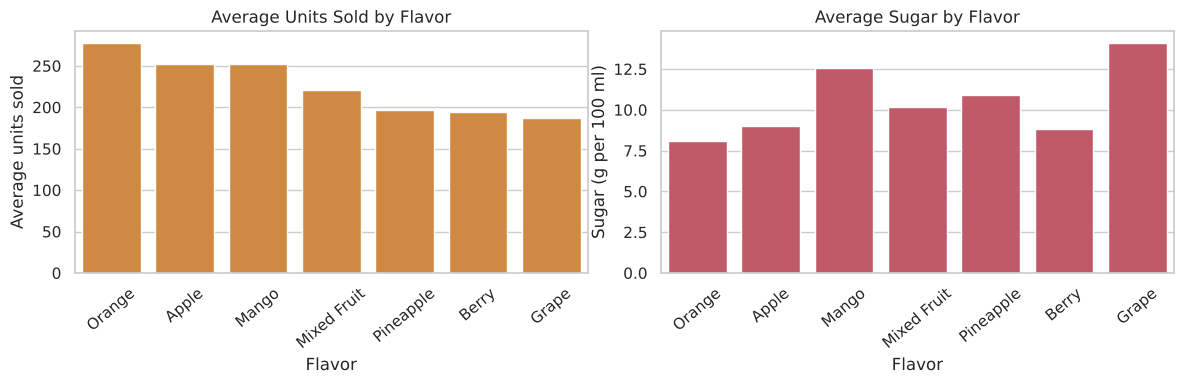

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = cat_summary.index
sns.barplot(data=clean, x="category", y="quantity_sold", order=order, ax=axes[0], color="#e8892b", errorbar=None)
axes[0].set_title("Average Units Sold by Flavor")
axes[0].set_xlabel("Flavor")
axes[0].set_ylabel("Average units sold")
axes[0].tick_params(axis="x", rotation=40)

sns.barplot(data=clean, x="category", y="sugar_g_per_100ml", order=order, ax=axes[1], color="#d1495b", errorbar=None)
axes[1].set_title("Average Sugar by Flavor")
axes[1].set_xlabel("Flavor")
axes[1].set_ylabel("Sugar (g per 100 ml)")
axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout()
plt.savefig("../images/category_comparison.png", dpi=120)
plt.show()

Orange sells the most per record (about 278 units) and has the lowest sugar. Grape has the highest sugar (about 14 g/100 ml) and one of the lowest sales. Sugar and sales look linked, but sugar differs mostly *between flavors*, so I can't tell from this chart whether sugar itself matters or whether it's just the flavor.

### 6.6 Does time of year or region matter?

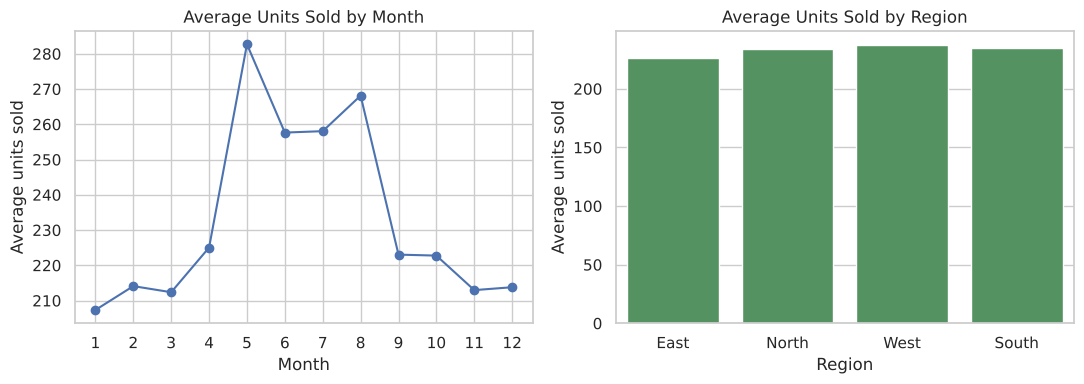

In [19]:
monthly = clean.groupby("month")["quantity_sold"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(monthly.index, monthly.values, marker="o")
axes[0].set_title("Average Units Sold by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Average units sold")
axes[0].set_xticks(range(1, 13))

sns.barplot(data=clean, x="region", y="quantity_sold", ax=axes[1], color="#4a9d5b", errorbar=None)
axes[1].set_title("Average Units Sold by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Average units sold")
plt.tight_layout()
plt.savefig("../images/month_region.png", dpi=120)
plt.show()

Sales rise from May to August, which looks like a summer effect. The four regions are very similar (about 226 to 237 units), so I leave `region` out of the model.

### 6.7 Correlation between numerical features

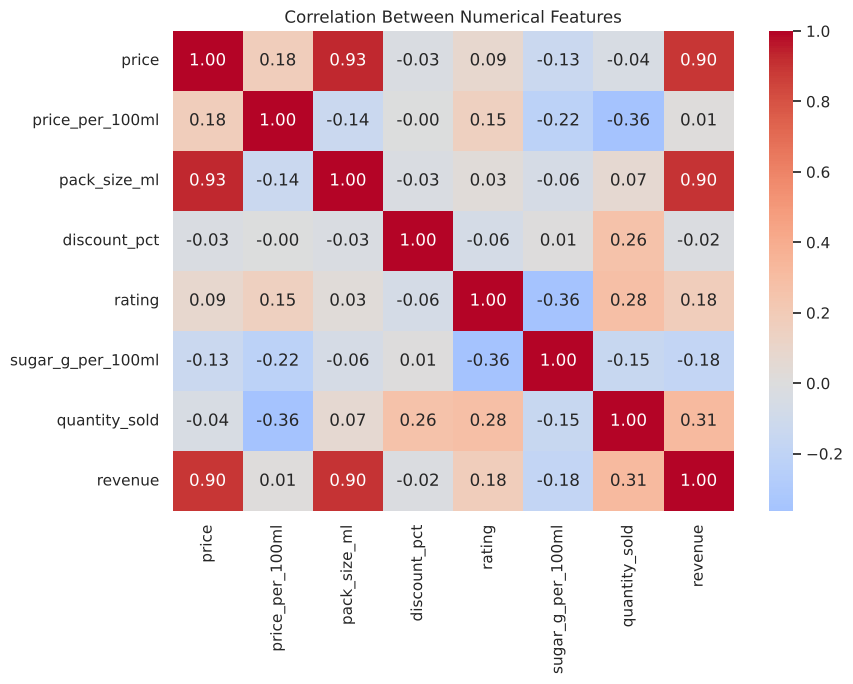

In [20]:
num_cols = ["price", "price_per_100ml", "pack_size_ml", "discount_pct",
            "rating", "sugar_g_per_100ml", "quantity_sold", "revenue"]

plt.figure(figsize=(9, 7))
sns.heatmap(clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=120)
plt.show()

- `price_per_100ml` has the strongest correlation with `quantity_sold` of the numeric columns.
- `price` and `revenue` are strongly correlated (about 0.9) because revenue is calculated from price.
- `revenue` contains `quantity_sold` in its formula, so I **must not** use it to predict `quantity_sold`: that would be data leakage.

## 7. Feature Preparation

- **Target (y):** `quantity_sold`, a number, so this is a regression problem.
- **Features (X):** price per 100 ml, pack size, discount, rating, sugar, organic flag, a summer flag (months 5-8, from the monthly chart) and flavor.
- **Left out:** `revenue` (leakage), `price` (price per 100 ml captures it better), `product_name` (too many unique values and flavor is already included), `region` (no visible effect), `month` (replaced by the summer flag).
- **Flavor is text**, and models need numbers, so I use one-hot encoding. `drop_first=True` removes one flavor (Apple) to avoid redundant columns; the other flavors are then compared to Apple.

In [21]:
model_df = clean.copy()
model_df["is_summer"] = model_df["month"].between(5, 8)

numeric_features = ["price_per_100ml", "pack_size_ml", "discount_pct", "rating", "sugar_g_per_100ml"]
X = model_df[numeric_features + ["is_organic", "is_summer", "category"]]
X = pd.get_dummies(X, columns=["category"], drop_first=True, dtype=int)
X[["is_organic", "is_summer"]] = X[["is_organic", "is_summer"]].astype(int)
y = model_df["quantity_sold"]

print("X shape:", X.shape, "| y shape:", y.shape)
X.head()

X shape: (640, 13) | y shape: (640,)


   price_per_100ml  pack_size_ml  discount_pct  rating  sugar_g_per_100ml  is_organic  is_summer  category_Berry  category_Grape  category_Mango  category_Mixed Fruit  category_Orange  category_Pineapple
0            6.412           250             0     4.7               13.6           0          0               0               0               1                     0                0                   0
1            6.824           250            10     4.1                9.4           0          0               1               0               0                     0                0                   0
2            6.420           200            10     3.8               14.4           1          0               0               1               0                     0                0                   0
3            4.742          1000             0     3.4               12.3           0          0               0               0               0                     1                0 

## 8. Train-Test Split

I keep 20% of the data hidden from the model so I can test it on rows it has never seen. `random_state=42` makes the split the same every time.

Numeric features are **scaled** (mean 0, standard deviation 1) so their coefficients are comparable. The scaler is fitted on the **training data only**; fitting on all data would let information from the test set leak in.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(X_train[numeric_features])
X_train, X_test = X_train.copy(), X_test.copy()
X_train[numeric_features] = scaler.transform(X_train[numeric_features])
X_test[numeric_features] = scaler.transform(X_test[numeric_features])

print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 512 | Test rows: 128


## 9. Machine Learning Model

**Linear Regression**: it learns one weight (coefficient) per feature and predicts `quantity_sold` as a weighted sum plus an intercept. I chose it because the target is a number, the model is simple, and every coefficient can be explained.

In [23]:
model = LinearRegression()
model.fit(X_train, y_train)

coefs = pd.Series(model.coef_, index=X_train.columns).sort_values(key=abs, ascending=False)
print("Intercept:", round(model.intercept_, 1))
coefs.round(2)

Intercept: 247.9


category_Grape         -73.01
category_Berry         -59.89
category_Pineapple     -55.96
is_summer               47.98
category_Mixed Fruit   -25.11
is_organic             -22.60
category_Mango         -21.65
price_per_100ml        -19.21
category_Orange         16.84
discount_pct            15.52
rating                  13.94
sugar_g_per_100ml        6.36
pack_size_ml             1.80

## 10. Model Evaluation

In [24]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model: Linear Regression")
print(f"MAE  : {mae:.2f}  (average error in units)")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}  (typical error, punishes big misses more)")
print(f"R2   : {r2:.3f}  (share of variation in sales explained)")
print(f"Average units sold in test set: {y_test.mean():.1f}")

Model: Linear Regression
MAE  : 25.91  (average error in units)
MSE  : 1094.26
RMSE : 33.08  (typical error, punishes big misses more)
R2   : 0.681  (share of variation in sales explained)
Average units sold in test set: 230.8


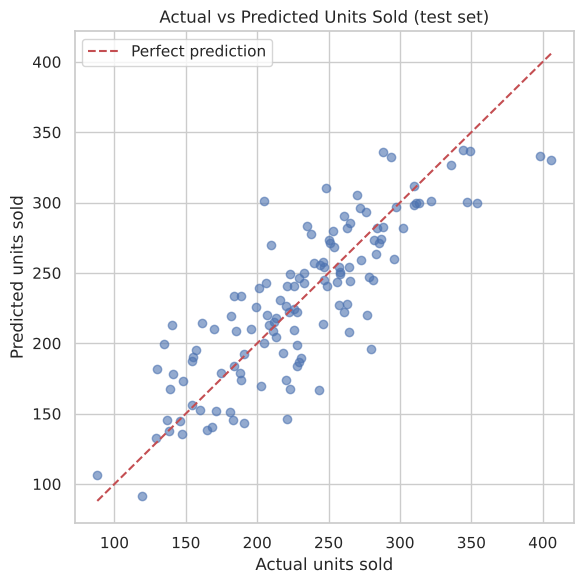

In [25]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.title("Actual vs Predicted Units Sold (test set)")
plt.xlabel("Actual units sold")
plt.ylabel("Predicted units sold")
plt.legend()
plt.tight_layout()
plt.savefig("../images/actual_vs_predicted.png", dpi=120)
plt.show()

## 11. Predictions

In [26]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.round(0).astype(int),
})
results["Error"] = results["Predicted"] - results["Actual"]
results.head(10)

   Actual  Predicted  Error
0     247        254      7
1     216        231     15
2     297        297      0
3     221        241     20
4     347        300    -47
5     281        245    -36
6     168        141    -27
7     226        225     -1
8     130        182     52
9     231        190    -41

## 12. Key Findings

Remember the data is simulated, so these describe *this dataset*, not the real juice market.

1. **Flavor is a major driver of sales.** Orange sells the most per record; Grape, Berry and Pineapple sell the least (the model's flavor coefficients are the largest in size).
2. **Price per 100 ml matters, raw price doesn't.** Raw price is mostly bottle size. Price per ml has a clear negative link with units sold.
3. **Summer months sell more**, with the highest averages from May to August.
4. **Organic juices sell fewer units** on average in this dataset (about 208 vs 244).
5. **Region has almost no effect.**
6. **Model result:** Linear Regression gets R² of about 0.68 on the test set, with an average error (MAE) of about 26 units on sales that average about 230. That is a decent first model but far from perfect: roughly a third of the variation is still unexplained.

## 13. Conclusion

I cleaned a messy juice sales dataset, explored it with charts and trained a Linear Regression model that explains about two thirds of the variation in units sold. The most useful steps were cleaning inconsistent categories, creating `price_per_100ml`, and leaving out `revenue` to avoid leakage.

**Limits:** the dataset is simulated; there is one train-test split with no cross-validation; and Linear Regression assumes straight-line effects, so it can miss more complex patterns.

**Next steps:** run the same workflow on a real dataset, try cross-validation, and compare with a Random Forest.